In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn import preprocessing

from sklearn.pipeline import make_pipeline

from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

df = pd.read_csv("../data/forest+fires/forestfires.csv", delimiter=",")

In [2]:
# Split the data
from sklearn.model_selection import train_test_split

categorical_columns = ["month", "day"]
numerical_columns = ['X', 'Y', 'FFMC', 'DMC', 'DC', 'ISI', 'temp', 'RH', 'wind', 'rain']

X = df[categorical_columns + numerical_columns]
y = df["area"]

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

In [3]:
#Add Engineered features
#Calculations used to get BUI and FWI are based off of https://publications.gc.ca/collections/collection_2016/rncan-nrcan/Fo133-1-424-eng.pdf

def addBUI(X):
    df = X.copy()
    #BUI
    dmc = df['DMC']
    dc = df['DC']

    buiLower = (0.8*dmc*dc)/(dmc+0.4*dc)
    buiHigher = dmc-(1.0-0.8*dc/(dmc+0.4*dc))*(0.92+(0.0114*dmc)**1.7)

    bui = np.where(dmc <= 0.4*dc, buiLower, buiHigher)

    df['BUI'] = bui
    return df

def addFWI(X):
    df = X.copy()
    #FWI
    isi = df['ISI']
    bui = df['BUI']

    fdLower = 0.626*bui**0.809 + 2.0
    fdHigher = 1000.0/(25.0+108.64*np.exp(-0.023*bui))
    Fd = np.where(bui <= 80, fdLower, fdHigher)

    b = 0.1*isi*Fd
    b = np.where(b<1, 1.0, b) #Safety in case
    fwi = np.where(b>0.1,np.exp(2.72*(0.434*np.log(b))**0.647),b)
    
    df['FWI'] = fwi
    return df

In [7]:
#Setting up Preprocessing Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, RobustScaler, OneHotEncoder, FunctionTransformer


categorical_pipe = make_pipeline(
    OneHotEncoder(handle_unknown="ignore")
)

numerical_pipe = make_pipeline(
    SimpleImputer(strategy="median")
)

preprocessing_all = make_pipeline(
    FunctionTransformer(addBUI),
    FunctionTransformer(addFWI),
    ColumnTransformer(
        [
            ("cat", categorical_pipe, categorical_columns),
            ("num", numerical_pipe, numerical_columns + ["BUI", "FWI"]),
        ]
    )
)

preprocessing_fire_weather_index = make_pipeline(
    FunctionTransformer(addBUI),
    FunctionTransformer(addFWI),
    ColumnTransformer(
        [
            ("num", numerical_pipe, ["FFMC", "DMC", "DC", "ISI", "BUI", "FWI"]),
        ]
    )
)

--------------PREPROCESSING:  ALL --------------
Model:  Mean 
Mean Absolute Error:  21.33978393957464 
Root Mean Squared Error:  97.46955760716725 
R2 Score:  -0.002757468434611221 


Model:  Median 
Mean Absolute Error:  16.646846153846152 
Root Mean Squared Error:  98.68148218072433 
R2 Score:  -0.027848823816304602 


Model:  0 
Mean Absolute Error:  16.67330769230769 
Root Mean Squared Error:  98.75317245536975 
R2 Score:  -0.029342792672087503 


Model:  Linear Regression 
Mean Absolute Error:  22.921076219522888 
Root Mean Squared Error:  96.94496362838473 
R2 Score:  0.008007429515863529 


Model:  Ridge 
Mean Absolute Error:  21.62504452844726 
Root Mean Squared Error:  97.10772158026798 
R2 Score:  0.004673781151195988 


Model:  KNN n = 3  
Mean Absolute Error:  23.96182051282051 
Root Mean Squared Error:  97.55744123642383 
R2 Score:  -0.004566560365151462 


Model:  KNN n = 7  
Mean Absolute Error:  22.472069597069595 
Root Mean Squared Error:  97.02337123377038 
R2 Score:

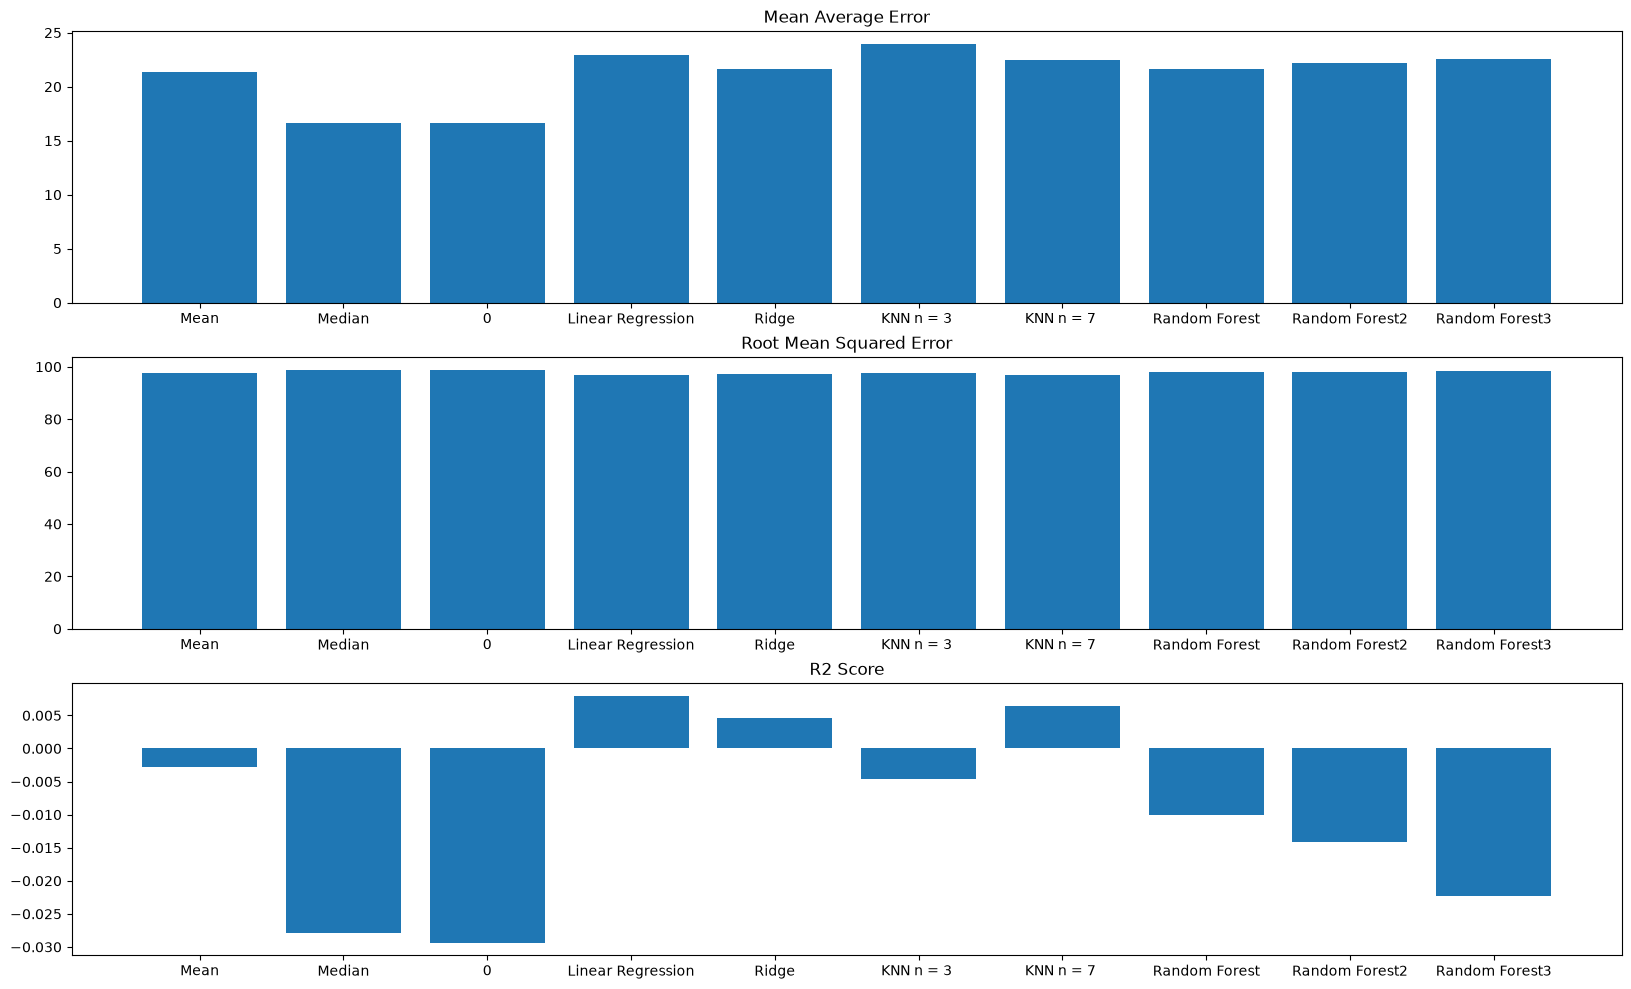

--------------PREPROCESSING:  FWI INDEX ONLY --------------
Model:  Mean 
Mean Absolute Error:  21.33978393957464 
Root Mean Squared Error:  97.46955760716725 
R2 Score:  -0.002757468434611221 


Model:  Median 
Mean Absolute Error:  16.646846153846152 
Root Mean Squared Error:  98.68148218072433 
R2 Score:  -0.027848823816304602 


Model:  0 
Mean Absolute Error:  16.67330769230769 
Root Mean Squared Error:  98.75317245536975 
R2 Score:  -0.029342792672087503 


Model:  Linear Regression 
Mean Absolute Error:  22.264231846468423 
Root Mean Squared Error:  97.89316340670406 
R2 Score:  -0.011492440255711278 


Model:  Ridge 
Mean Absolute Error:  21.942781795047477 
Root Mean Squared Error:  97.80932143242725 
R2 Score:  -0.009760568411618875 


Model:  KNN n = 3  
Mean Absolute Error:  18.758820512820513 
Root Mean Squared Error:  89.12723454865295 
R2 Score:  0.16154689335933925 


Model:  KNN n = 7  
Mean Absolute Error:  22.87972161172161 
Root Mean Squared Error:  97.1044934443037

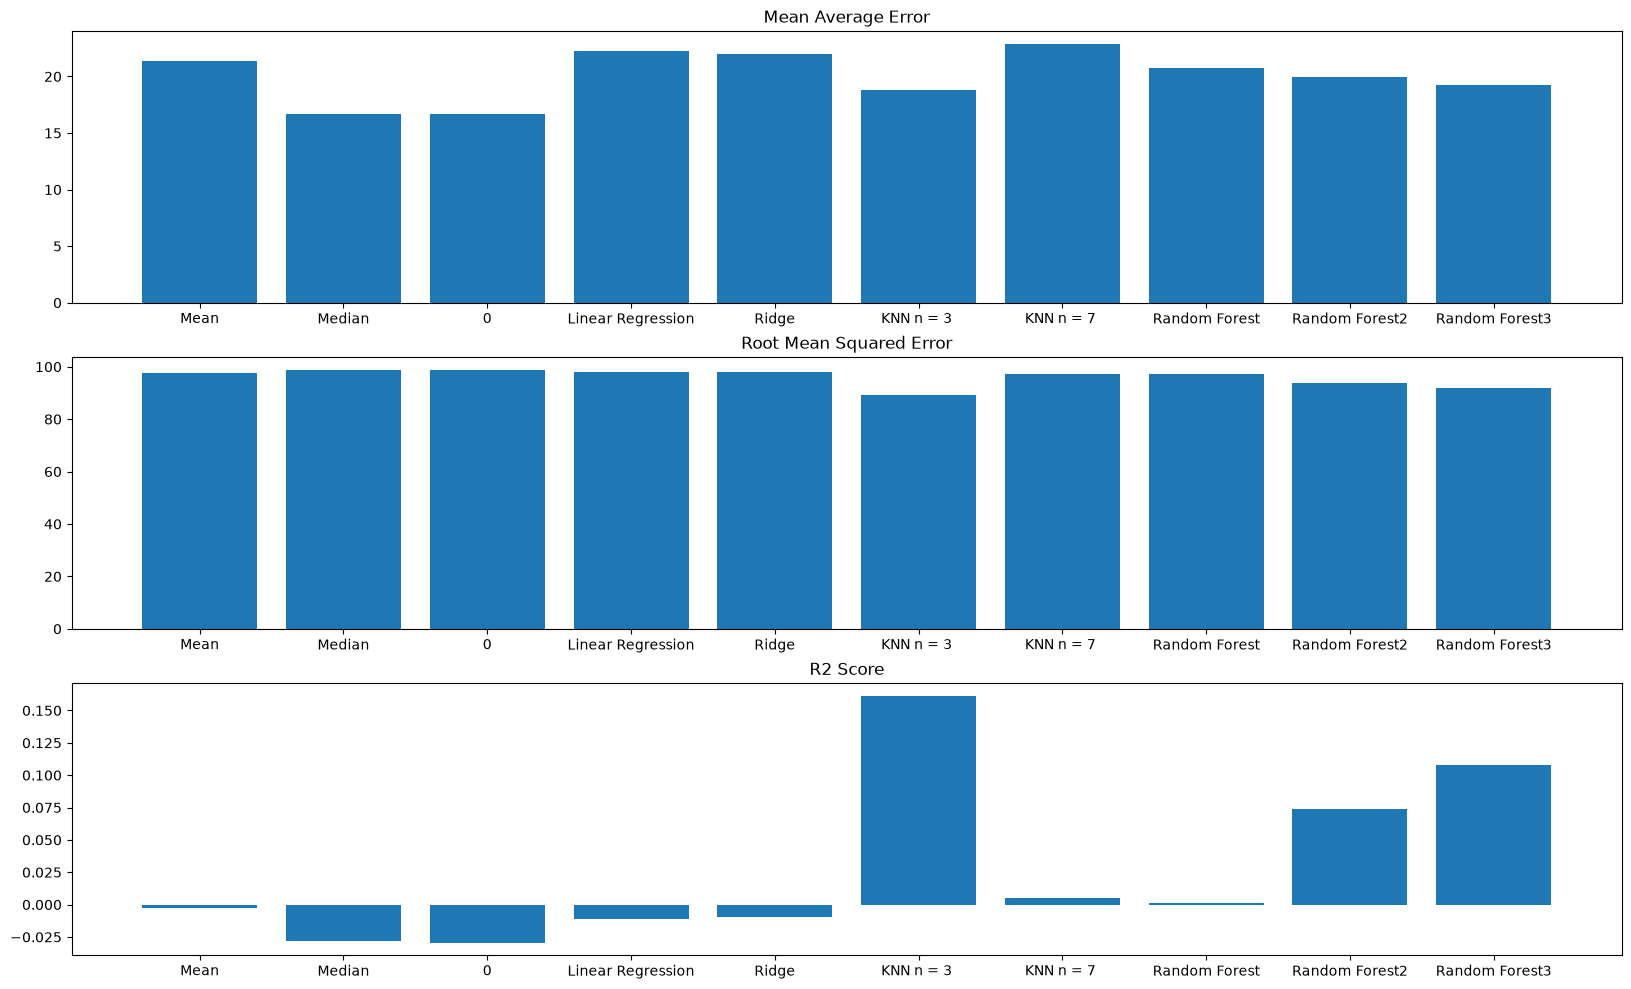

In [8]:
# Trying Different Models and preprocessing pipelines
from sklearn.linear_model import LinearRegression, RidgeCV, GammaRegressor
from sklearn.dummy import DummyRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor

preprocessing_pipelines = {
    "ALL" : preprocessing_all,
    "FIRE WEATHER INDEX ONLY": preprocessing_fire_weather_index
}

models = {
    "Mean" : DummyRegressor(strategy="mean"),
    "Median" : DummyRegressor(strategy="median"),
    "0" : DummyRegressor(strategy="constant", constant = 0.0),
    "Linear Regression": LinearRegression(),
    "Ridge" : RidgeCV(alphas=[0.01,0.1,1,10,100]),
    "KNN n = 3" : KNeighborsRegressor(n_neighbors=3), # Tried changing weights to "Distance", small negative impact on results
    "KNN n = 7" : KNeighborsRegressor(n_neighbors=7),
    "KNN n = 21" : KNeighborsRegressor(n_neighbors=21),
    "Random Forest": RandomForestRegressor(max_depth=2, random_state=123),
    "Random Forest 2": RandomForestRegressor(max_depth=5, random_state=123),
    "Random Forest 3": RandomForestRegressor(max_depth=10, random_state=123)
#    "Gamma Regressor": GammaRegressor() Doesn't work due to the 0s, normalisation fixes?
}

for title, preprocessing in preprocessing_pipelines.items():
    print("--------------PREPROCESSING: ", title,"--------------")

    resultsMAE =[]
    resultsRMSE = []
    resultsR2 = []
    # Run all of the models and print out their results
    for name, model in models.items():
        model = make_pipeline(preprocessing, model)
        model.fit(X_train, y_train)
        pred = model.predict(X_test)

        mae = mean_absolute_error(y_test, pred)
        rmse = root_mean_squared_error(y_test, pred)
        r2 = r2_score(y_test, pred)
    
        resultsMAE.append(mae)
        resultsRMSE.append(rmse)
        resultsR2.append(r2)
    
        print("Model: ", name ,"\nMean Absolute Error: ", mae, "\nRoot Mean Squared Error: ", rmse,"\nR2 Score: ", r2 ,"\n\n")
    
    plt.figure(figsize={len(models.keys()) * 2,12}) ##Figure is dynamically sized to allow for more models to be added as needed
    
    plt.subplot(311, title="Mean Average Error").bar(range(len(resultsMAE)),resultsMAE)
    plt.xticks(range(len(models.keys())),models.keys())
    
    plt.subplot(312, title="Root Mean Squared Error").bar(range(len(resultsRMSE)),resultsRMSE)
    plt.xticks(range(len(models.keys())),models.keys())
    
    plt.subplot(313, title="R2 Score").bar(range(len(resultsR2)),resultsR2)
    plt.xticks(range(len(models.keys())),models.keys())

    plt.show()

Median seems like the best baseline when ran against all columns, very low R2 score though

KNN n = 3 gets a much better R2 Score when ran using only the FWI values